<a href="https://colab.research.google.com/github/mithulkannan17/Machine_learning_2/blob/main/K_Means_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET INFORMATION

Dataset loaded successfully!

Dataset Shape:
(53940, 10)

First 5 Rows:
   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x  

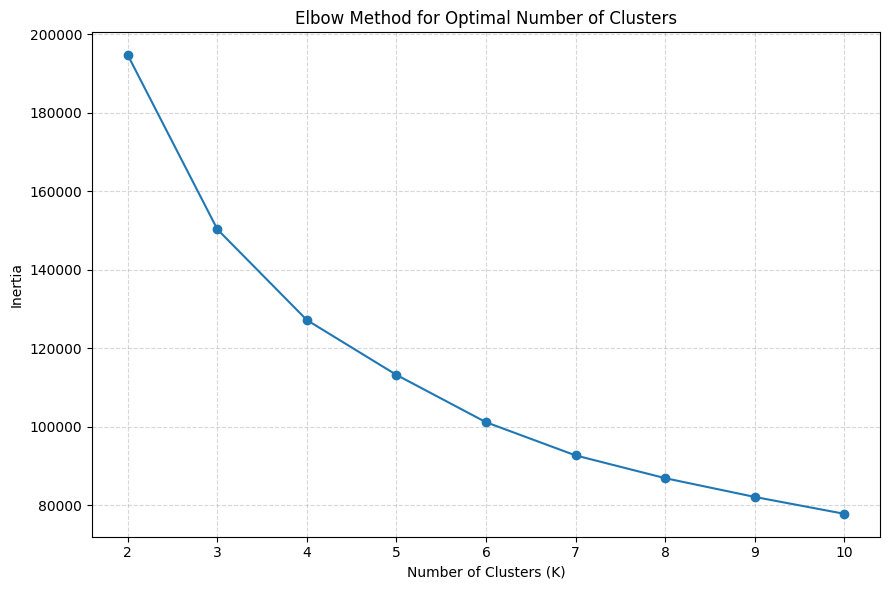


K-MEANS CLUSTERING RESULTS

Number of clusters: 3

Cluster counts:
Cluster
0    21816
1     7211
2    24913
Name: count, dtype: int64

Silhouette Score:
0.3718

First 10 clustered samples:
   carat  depth  table  price     x     y     z  Cluster
0   0.23   61.5   55.0    326  3.95  3.98  2.43        2
1   0.21   59.8   61.0    326  3.89  3.84  2.31        2
2   0.23   56.9   65.0    327  4.05  4.07  2.31        2
3   0.29   62.4   58.0    334  4.20  4.23  2.63        2
4   0.31   63.3   58.0    335  4.34  4.35  2.75        2
5   0.24   62.8   57.0    336  3.94  3.96  2.48        2
6   0.24   62.3   57.0    336  3.95  3.98  2.47        2
7   0.26   61.9   55.0    337  4.07  4.11  2.53        2
8   0.22   65.1   61.0    337  3.87  3.78  2.49        2
9   0.23   59.4   61.0    338  4.00  4.05  2.39        2

CLUSTER CENTERS
      carat      depth      table         price         x         y         z
0  0.951158  61.825143  57.839561   4521.620168  6.273565  6.271718  3.876988
1  1.70249

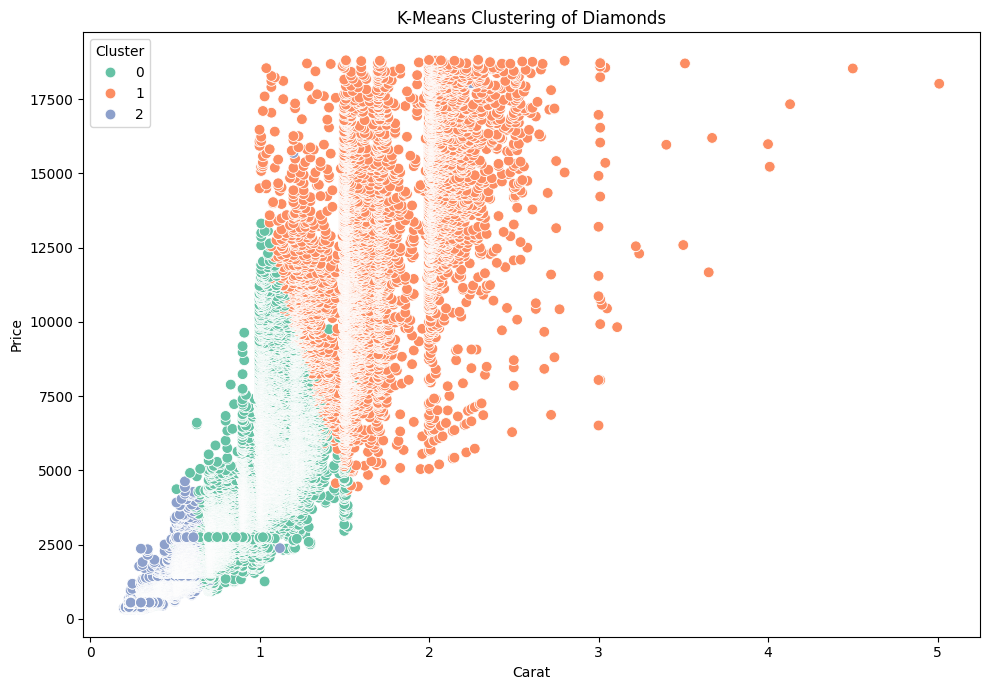

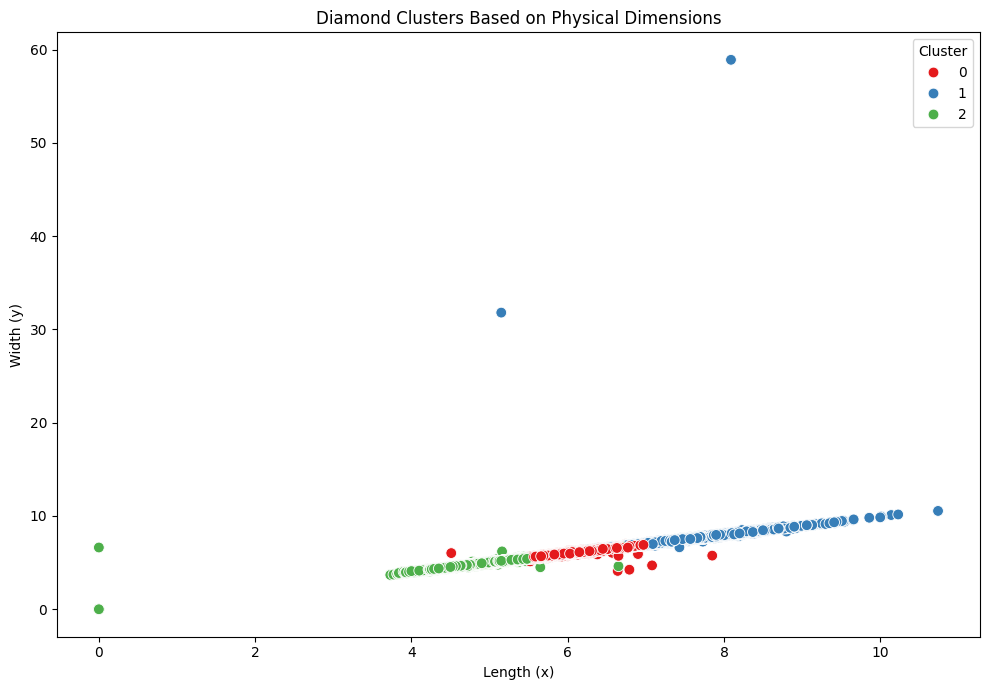


EXPERIMENT COMPLETED

K-Means clustering was successfully applied to the
Seaborn Diamonds dataset.

The diamonds were grouped into clusters based on
similarity in their numerical characteristics.

The Elbow Method was used to study the suitable
number of clusters.

The resulting clusters were visualized using
scatter plots.

The Silhouette Score was also calculated to
measure the quality of clustering.



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
df = pd.read_csv(url)

print("DATASET INFORMATION")
print("\nDataset loaded successfully!")
print("\nDataset Shape:")
print(df.shape)
print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())

df = df.dropna()
print("\nShape after removing missing values:")
print(df.shape)

features = [
    "carat",
    "depth",
    "table",
    "price",
    "x",
    "y",
    "z"
]
X = df[features]
print("\nFeatures used for clustering:")
print(features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("\nFeatures standardized successfully.")

inertia = []
K_range = range(2, 11)
for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(9, 6))
plt.plot(
    K_range,
    inertia,
    marker="o"
)
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(K_range)
plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)
plt.tight_layout()
plt.show()

optimal_k = 3
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)
clusters = kmeans.fit_predict(X_scaled)
df["Cluster"] = clusters

print("\nK-MEANS CLUSTERING RESULTS")
print("\nNumber of clusters:", optimal_k)
print("\nCluster counts:")
print(
    df["Cluster"].value_counts().sort_index()
)

silhouette = silhouette_score(
    X_scaled,
    clusters
)
print("\nSilhouette Score:")
print(round(silhouette, 4))

print("\nFirst 10 clustered samples:")
print(
    df[
        [
            "carat",
            "depth",
            "table",
            "price",
            "x",
            "y",
            "z",
            "Cluster"
        ]
    ].head(10)
)

cluster_centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)
centers_df = pd.DataFrame(
    cluster_centers,
    columns=features
)
print("\nCLUSTER CENTERS")
print(centers_df)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df,
    x="carat",
    y="price",
    hue="Cluster",
    palette="Set2",
    s=60
)
plt.title("K-Means Clustering of Diamonds")
plt.xlabel("Carat")
plt.ylabel("Price")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df,
    x="x",
    y="y",
    hue="Cluster",
    palette="Set1",
    s=60
)
plt.title("Diamond Clusters Based on Physical Dimensions")
plt.xlabel("Length (x)")
plt.ylabel("Width (y)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("\nEXPERIMENT COMPLETED")
print("""
K-Means clustering was successfully applied to the
Seaborn Diamonds dataset.

The diamonds were grouped into clusters based on
similarity in their numerical characteristics.

The Elbow Method was used to study the suitable
number of clusters.

The resulting clusters were visualized using
scatter plots.

The Silhouette Score was also calculated to
measure the quality of clustering.
""")

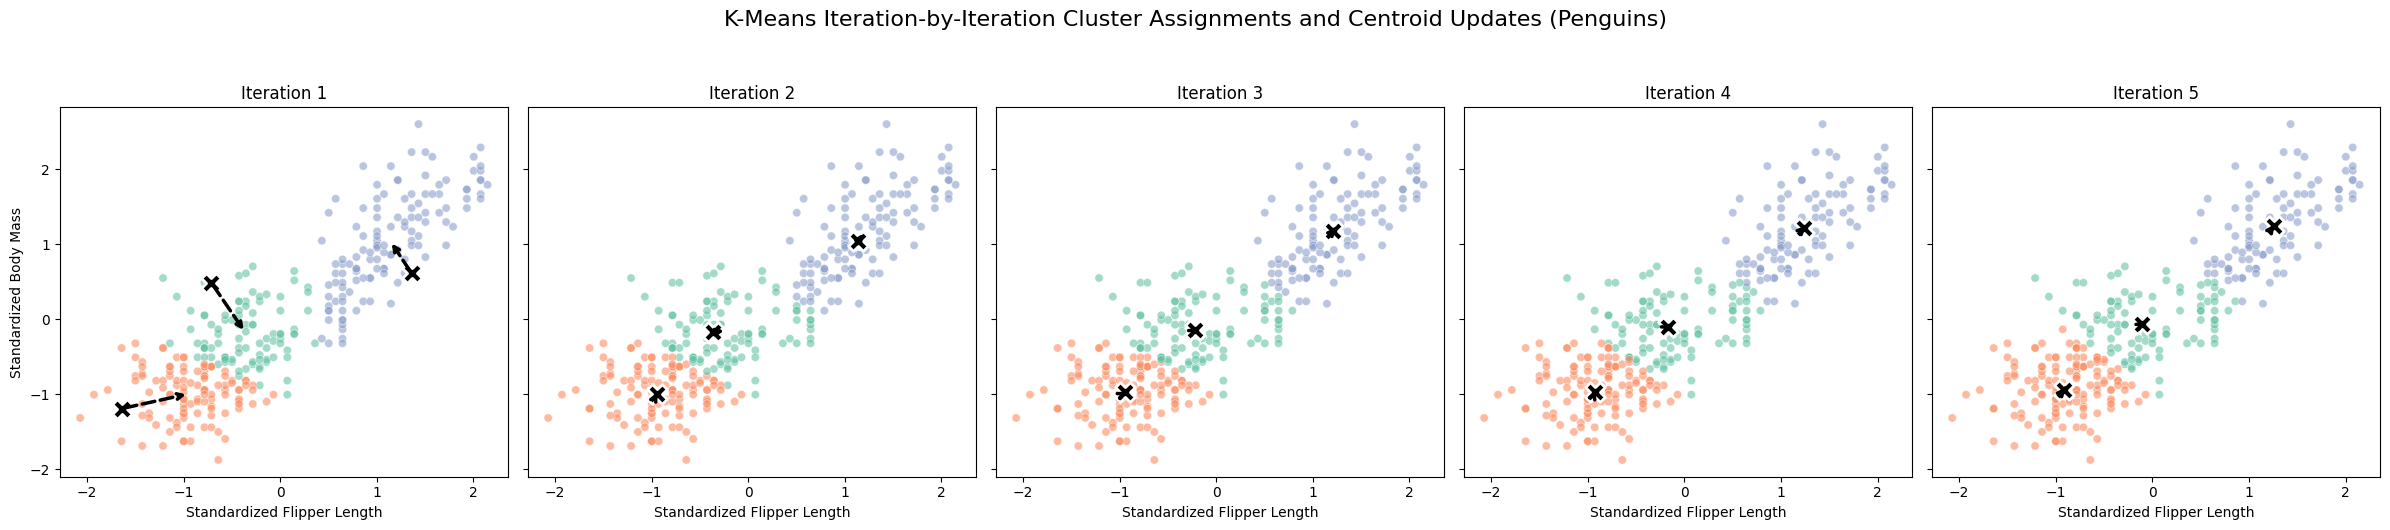

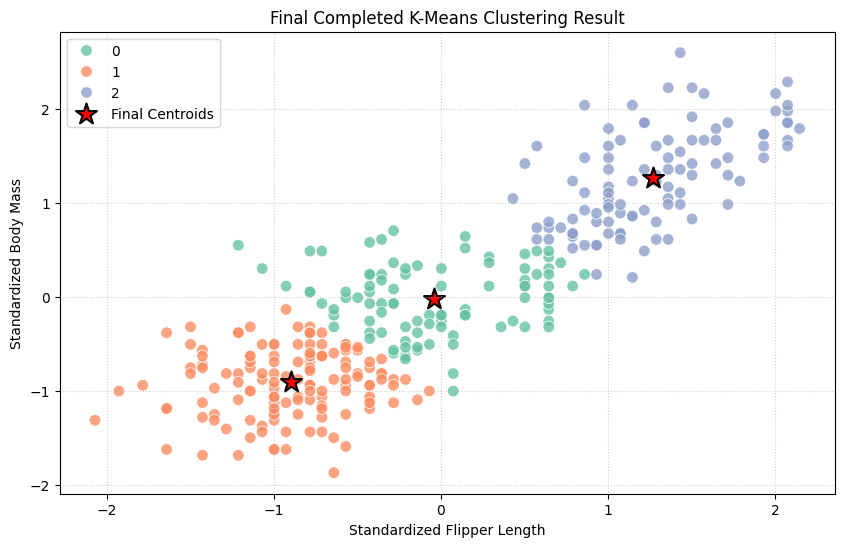

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df_penguins = pd.read_csv(url).dropna()

features = ["flipper_length_mm", "body_mass_g"]
X = df_penguins[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

np.random.seed(123)
k = 3

initial_indices = np.random.choice(X_scaled.shape[0], k, replace=False)
centroids = X_scaled[initial_indices]

max_iterations = 5

centroids_history = [centroids.copy()]
clusters_history = []

for iteration in range(max_iterations):
    distances = np.linalg.norm(X_scaled[:, np.newaxis] - centroids, axis=2)
    cluster_assignments = np.argmin(distances, axis=1)
    clusters_history.append(cluster_assignments)

    new_centroids = np.zeros_like(centroids)
    for i in range(k):
        points_in_cluster = X_scaled[cluster_assignments == i]
        if len(points_in_cluster) > 0:
            new_centroids[i] = points_in_cluster.mean(axis=0)
        else:
            new_centroids[i] = centroids[i]

    centroids = new_centroids
    centroids_history.append(centroids.copy())

fig, axes = plt.subplots(1, max_iterations, figsize=(24, 5), sharex=True, sharey=True)

for i in range(max_iterations):
    ax = axes[i]
    current_clusters = clusters_history[i]
    current_centroids = centroids_history[i]
    next_centroids = centroids_history[i+1]

    sns.scatterplot(
        x=X_scaled[:, 0],
        y=X_scaled[:, 1],
        hue=current_clusters,
        palette="Set2",
        legend=False,
        alpha=0.6,
        ax=ax
    )

    ax.scatter(
        current_centroids[:, 0],
        current_centroids[:, 1],
        c='black',
        s=200,
        marker='X',
        edgecolor='white',
        linewidth=2
    )

    for c_idx in range(k):
        ax.annotate(
            '',
            xy=(next_centroids[c_idx, 0], next_centroids[c_idx, 1]),
            xytext=(current_centroids[c_idx, 0], current_centroids[c_idx, 1]),
            arrowprops=dict(arrowstyle="->", color="black", lw=2.5, ls="--")
        )

    ax.set_title(f"Iteration {i + 1}")
    ax.set_xlabel("Standardized Flipper Length")
    if i == 0:
        ax.set_ylabel("Standardized Body Mass")

plt.suptitle("K-Means Iteration-by-Iteration Cluster Assignments and Centroid Updates (Penguins)", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=clusters_history[-1],
    palette="Set2",
    alpha=0.8,
    s=70
)
plt.scatter(
    centroids_history[-1][:, 0],
    centroids_history[-1][:, 1],
    c='red',
    s=250,
    marker='*',
    edgecolor='black',
    linewidth=1.5,
    label='Final Centroids'
)
plt.title("Final Completed K-Means Clustering Result")
plt.xlabel("Standardized Flipper Length")
plt.ylabel("Standardized Body Mass")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

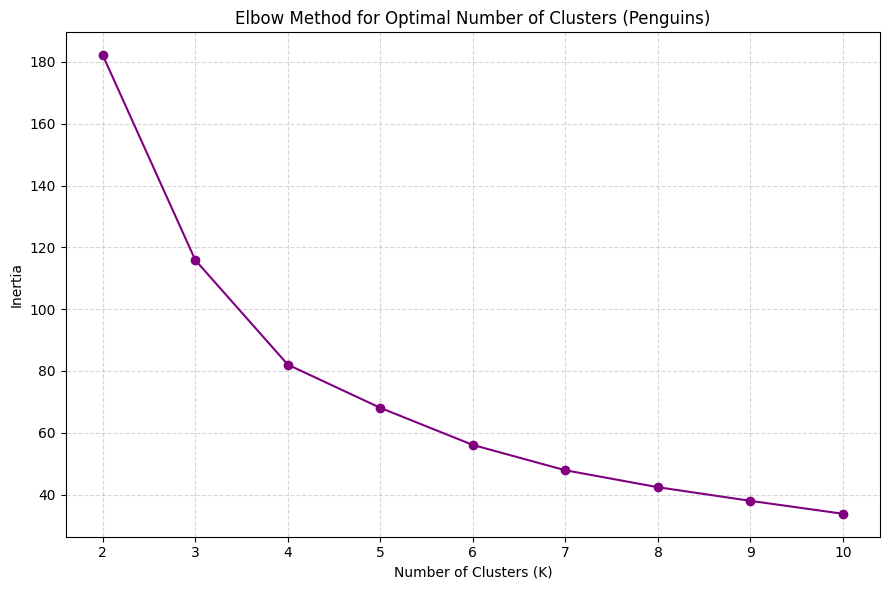

In [4]:
from sklearn.cluster import KMeans

# Calculate inertia for different values of K on the penguins dataset
penguin_inertia = []
K_range_penguins = range(2, 11)

for k_val in K_range_penguins:
    km = KMeans(n_clusters=k_val, random_state=42, n_init=10)
    km.fit(X_scaled)
    penguin_inertia.append(km.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(9, 6))
plt.plot(K_range_penguins, penguin_inertia, marker='o', color='purple')
plt.title('Elbow Method for Optimal Number of Clusters (Penguins)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(K_range_penguins)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()